In [2]:
# import the labraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("import labraries succussful")

import labraries succussful


In [5]:
# load the dataset
df = pd.read_csv(r"C:\Users\Nitro V15\Documents\Internship_projects\sentiment_analysis_pro2\dataset\reviews.csv")
print("load data succesfully")

load data succesfully


In [6]:
# disply first five records
df.head()

,review_id,review_text,sentiment,category,source
0,1,This product exceeded my expectations in sever...,Positive,Books,Online Store
1,2,The item is uncomfortable to use and poorly de...,Negative,Books,Online Store
2,3,The product comes with a charging adapter and ...,Neutral,Travel,Customer Survey
3,4,Customer support was slow and did not solve my...,Negative,Home & Kitchen,Website
4,5,"The design is simple, attractive, and comforta...",Positive,Sports,Online Store


In [7]:
# check dataset diamenstion
print("number of rows:",df.shape[0])
print("number of column:",df.shape[1])

number of rows: 10000
number of column: 5


In [8]:
# display the column name
print(df.columns.tolist())

['review_id', 'review_text', 'sentiment', 'category', 'source']


In [9]:
# check the datatype
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   review_id    10000 non-null  int64 
 1   review_text  10000 non-null  object
 2   sentiment    10000 non-null  object
 3   category     10000 non-null  object
 4   source       10000 non-null  object
dtypes: int64(1), object(4)
memory usage: 390.8+ KB


In [10]:
# check the missing value
print(df.isnull().sum())

review_id      0
review_text    0
sentiment      0
category       0
source         0
dtype: int64


In [11]:
# check the duplicates recorad
print("duplicate rows:",df.duplicated().sum())

duplicate rows: 0


In [15]:
# count the each sentiment class
print(df["sentiment"].value_counts())

sentiment
Positive    3334
Negative    3333
Neutral     3333
Name: count, dtype: int64


In [63]:
df_unique[df_unique["sentiment"] == "Negative"][["review_text", "sentiment"]].head(10)

,review_text,sentiment
1,The item is uncomfortable to use and poorly de...,Negative
3,Customer support was slow and did not solve my...,Negative
5,The delivery was late and the package arrived ...,Negative
11,The order was incorrect and fixing it took too...,Negative
12,The packaging was poor and some parts were mis...,Negative
15,The item is uncomfortable to use and poorly de...,Negative
16,The service was disappointing and the staff we...,Negative
18,I am unhappy with the product and would not pu...,Negative
19,The item feels cheaply made and does not perfo...,Negative
21,The product stopped working after only a few d...,Negative


In [64]:
df_unique[
    df_unique["review_text"].str.contains(
        "damaged|bad|poor|terrible",
        case=False,
        na=False
    )
][["review_text", "sentiment"]]

,review_text,sentiment
1,The item is uncomfortable to use and poorly de...,Negative
5,The delivery was late and the package arrived ...,Negative
12,The packaging was poor and some parts were mis...,Negative
15,The item is uncomfortable to use and poorly de...,Negative
58,The packaging was poor and some parts were mis...,Negative
139,I am disappointed with this purchase because t...,Negative
169,I am disappointed with this purchase because t...,Negative
225,The packaging was poor and some parts were mis...,Negative
233,The item is uncomfortable to use and poorly de...,Negative
249,The delivery was late and the package arrived ...,Negative


In [65]:
import pandas as pd

extra_reviews = pd.DataFrame({
    "review_text": [
        "This product is bad quality",
        "The delivered product was damaged",
        "The product is broken and unusable",
        "I am unhappy with this purchase",
        "The quality is poor and disappointing",
        "The product stopped working",
        "I hate this product",
        "The service was terrible",
        "The product is excellent",
        "I love the quality of this product",
        "The product works perfectly",
        "I am very happy with my purchase",
        "The service was outstanding",
        "This is a wonderful product",
        "The quality is amazing",
        "The package arrived today",
        "The product comes with a user manual",
        "The order contains a phone and charger",
        "The product was delivered yesterday",
        "The package contains three items"
    ],
    "sentiment": [
        "Negative", "Negative", "Negative", "Negative",
        "Negative", "Negative", "Negative", "Negative",
        "Positive", "Positive", "Positive", "Positive",
        "Positive", "Positive", "Positive",
        "Neutral", "Neutral", "Neutral", "Neutral", "Neutral"
    ]
})

print("Additional reviews:", len(extra_reviews))
print(extra_reviews["sentiment"].value_counts())

Additional reviews: 20
sentiment
Negative    8
Positive    7
Neutral     5
Name: count, dtype: int64


In [16]:
# Calculate Sentiment Percentages
print(df["sentiment"].value_counts(normalize=True).mul(100).round(2))

sentiment
Positive    33.34
Negative    33.33
Neutral     33.33
Name: proportion, dtype: float64


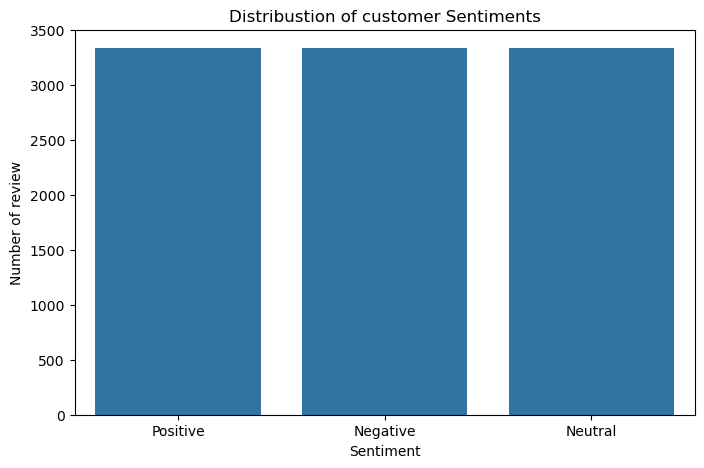

In [18]:
# Visualize Sentiment Distribution
plt.figure(figsize=(8,5))
sns.countplot(data=df,x="sentiment")
plt.title("Distribustion of customer Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of review")
plt.show()

### Exploratory Data Analysis (EDA)

In [21]:
# Check unique review texts
unique_reviews = df['review_text'].nunique()
print("total_review:",len(df))
print("unique_review_text:",unique_reviews)
print("Repeated review entries:",len(df)- unique_reviews)

total_review: 10000
unique_review_text: 300
Repeated review entries: 9700


In [23]:
# Check whether identical reviews have different sentiment labels
review_label_counts = df.groupby("review_text")["sentiment"].nunique()
conflicting_reviews = (review_label_counts>1).sum()
print("Reviews with conflicting sentiment labels:",conflicting_reviews)

Reviews with conflicting sentiment labels: 0


In [25]:
# Calculate the length of each review
df["review_length"] = df["review_text"].astype(str).str.len()
# Display statistical summary
print(df["review_length"].describe())

count    10000.000000
mean        94.639100
std         21.700068
min         43.000000
25%         84.000000
50%         99.000000
75%        109.000000
max        136.000000
Name: review_length, dtype: float64


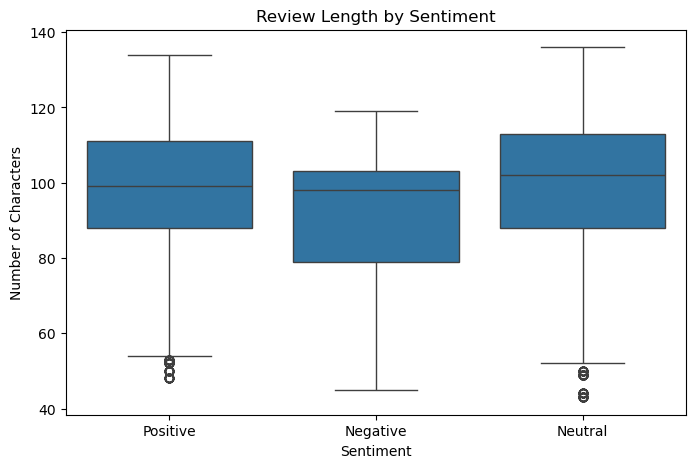

In [26]:
#Review Length Distribution by Sentiment

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="sentiment", y="review_length")
plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Characters")
plt.show()

In [27]:
# Method 16: Analyze Sentiment by Product Category
category_sentiment = pd.crosstab(df["category"],df["sentiment"])
print(category_sentiment)

sentiment       Negative  Neutral  Positive
category                                   
Beauty               432      450       390
Books                398      370       400
Clothing             466      398       424
Electronics          407      419       413
Food & Grocery       369      431       405
Home & Kitchen       408      407       430
Sports               416      446       416
Travel               437      412       456


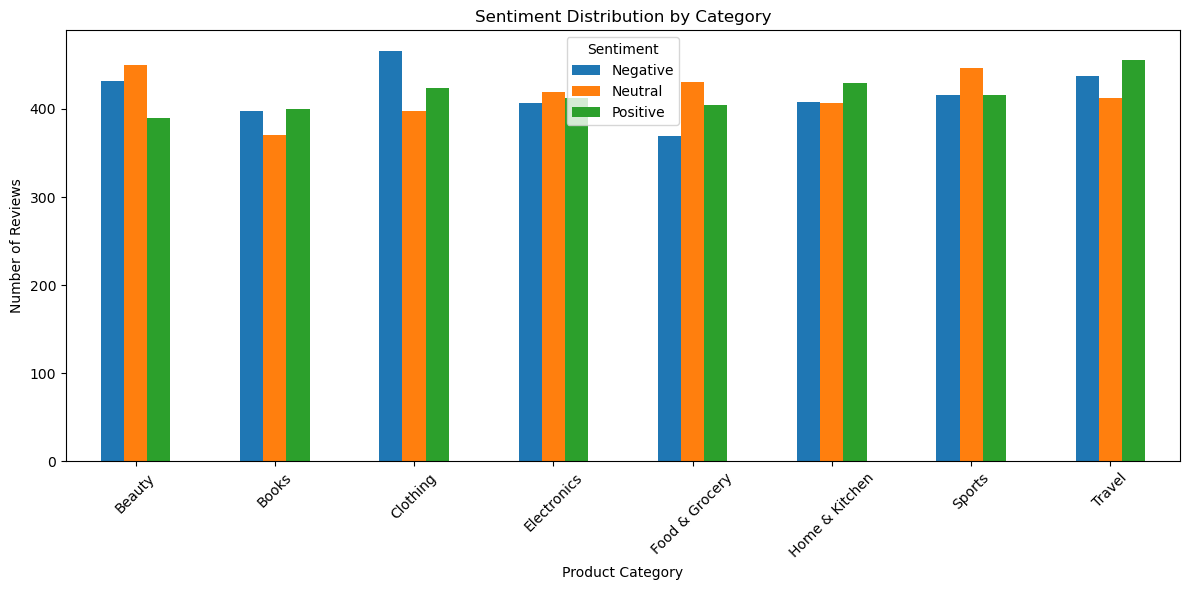

In [28]:
# Method 17: Visualize Sentiment by Category
category_sentiment.plot(kind="bar",figsize=(12, 6))
plt.title("Sentiment Distribution by Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

### Text Preprocessing

In [29]:
# Method 18: Convert text to lowercase
df["cleaned_text"] = df["review_text"].str.lower()
print(df[["review_text", "cleaned_text"]].head())

                                         review_text  \
0  This product exceeded my expectations in sever...   
1  The item is uncomfortable to use and poorly de...   
2  The product comes with a charging adapter and ...   
3  Customer support was slow and did not solve my...   
4  The design is simple, attractive, and comforta...   

                                        cleaned_text  
0  this product exceeded my expectations in sever...  
1  the item is uncomfortable to use and poorly de...  
2  the product comes with a charging adapter and ...  
3  customer support was slow and did not solve my...  
4  the design is simple, attractive, and comforta...  


In [31]:
import re
def clean_text(text):
    text = re.sub(r"[^a-zA-Z0-9\s]", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()
df["cleaned_text"] = df["cleaned_text"].apply(clean_text)
print(df[["review_text", "cleaned_text"]].head())

                                         review_text  \
0  This product exceeded my expectations in sever...   
1  The item is uncomfortable to use and poorly de...   
2  The product comes with a charging adapter and ...   
3  Customer support was slow and did not solve my...   
4  The design is simple, attractive, and comforta...   

                                        cleaned_text  
0  this product exceeded my expectations in sever...  
1  the item is uncomfortable to use and poorly de...  
2  the product comes with a charging adapter and ...  
3  customer support was slow and did not solve my...  
4  the design is simple attractive and comfortabl...  


In [32]:
# Check duplicate cleaned reviews
duplicate_count = df["cleaned_text"].duplicated().sum()
print("Duplicate cleaned texts:", duplicate_count)

Duplicate cleaned texts: 9700


In [33]:
# Compare original and cleaned reviews
df[["review_text", "cleaned_text"]].head(10)

,review_text,cleaned_text
0,This product exceeded my expectations in sever...,this product exceeded my expectations in sever...
1,The item is uncomfortable to use and poorly de...,the item is uncomfortable to use and poorly de...
2,The product comes with a charging adapter and ...,the product comes with a charging adapter and ...
3,Customer support was slow and did not solve my...,customer support was slow and did not solve my...
4,"The design is simple, attractive, and comforta...",the design is simple attractive and comfortabl...
5,The delivery was late and the package arrived ...,the delivery was late and the package arrived ...
6,This is one of the better purchases I have mad...,this is one of the better purchases i have mad...
7,The product works perfectly and feels well mad...,the product works perfectly and feels well mad...
8,Customer support responded quickly and solved ...,customer support responded quickly and solved ...
9,"The service was friendly, efficient, and profe...",the service was friendly efficient and profess...


### TF-IDF

In [34]:
#Convert Text into Numerical Features Using TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer
print("TF-IDF Vectorizer imported successfully!")

TF-IDF Vectorizer imported successfully!


In [35]:
# Create the TF-IDF vectorizer
tfidf = TfidfVectorizer(max_features=3000)
# Convert cleaned text into numerical features
X = tfidf.fit_transform(df["cleaned_text"])
# Display the shape of the TF-IDF matrix
print("TF-IDF Matrix Shape:", X.shape)

TF-IDF Matrix Shape: (10000, 266)


In [36]:
# Prepare Data for Model Training
# Create a dataset with unique cleaned reviews
df_unique = df.drop_duplicates(subset="cleaned_text").copy()

# Display dataset size before and after removing duplicate reviews
print("Original dataset shape:", df.shape)
print("Dataset shape after removing duplicate cleaned reviews:", df_unique.shape)

# Check sentiment distribution
print("\nSentiment distribution:")
print(df_unique["sentiment"].value_counts())

Original dataset shape: (10000, 7)
Dataset shape after removing duplicate cleaned reviews: (300, 7)

Sentiment distribution:
sentiment
Positive    100
Negative    100
Neutral     100
Name: count, dtype: int64


In [37]:
#Split Data into Training and Testing Sets
from sklearn.model_selection import train_test_split

# Prepare input text and target labels
X_text = df_unique["cleaned_text"]
y = df_unique["sentiment"]

# Split the data into training and testing sets
X_train_text, X_test_text, y_train, y_test = train_test_split(X_text,y,test_size=0.20,random_state=42,stratify=y)

# Display the dataset sizes
print("Training reviews:", len(X_train_text))
print("Testing reviews:", len(X_test_text))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Training reviews: 240
Testing reviews: 60

Training sentiment distribution:
sentiment
Negative    80
Neutral     80
Positive    80
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
Negative    20
Positive    20
Neutral     20
Name: count, dtype: int64


In [38]:
# Apply TF-IDF to Training and Testing Data
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
tfidf = TfidfVectorizer(max_features=3000)

# Learn vocabulary from training reviews and transform them
X_train = tfidf.fit_transform(X_train_text)

# Transform testing reviews using the same vocabulary
X_test = tfidf.transform(X_test_text)

# Display the results
print("Training feature matrix shape:", X_train.shape)
print("Testing feature matrix shape:", X_test.shape)
print("Number of TF-IDF features:", len(tfidf.get_feature_names_out()))

Training feature matrix shape: (240, 266)
Testing feature matrix shape: (60, 266)
Number of TF-IDF features: 266


In [39]:
# Train a Logistic Regression Model
from sklearn.linear_model import LogisticRegression
print("Logistic Regression imported successfully!")

Logistic Regression imported successfully!


In [40]:
# Create the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model
lr_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [42]:
# Predict sentiment for test reviews
y_pred = lr_model.predict(X_test)

# Display actual and predicted sentiments
results = pd.DataFrame({
    "Actual Sentiment": y_test.values,
    "Predicted Sentiment": y_pred
})

print(results.head(10))

  Actual Sentiment Predicted Sentiment
0         Negative            Negative
1         Negative            Negative
2         Positive            Positive
3         Positive            Positive
4         Positive            Positive
5         Negative            Negative
6          Neutral             Neutral
7         Negative            Negative
8         Positive            Positive
9         Negative            Negative


In [43]:
from sklearn.metrics import accuracy_score
# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Logistic Regression Accuracy:", round(accuracy * 100, 2), "%")

Logistic Regression Accuracy: 100.0 %


In [44]:
from sklearn.metrics import classification_report

# Generate the classification report
report = classification_report(y_test, y_pred)

print("Logistic Regression Classification Report:\n")
print(report)

Logistic Regression Classification Report:

              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        20
     Neutral       1.00      1.00      1.00        20
    Positive       1.00      1.00      1.00        20

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



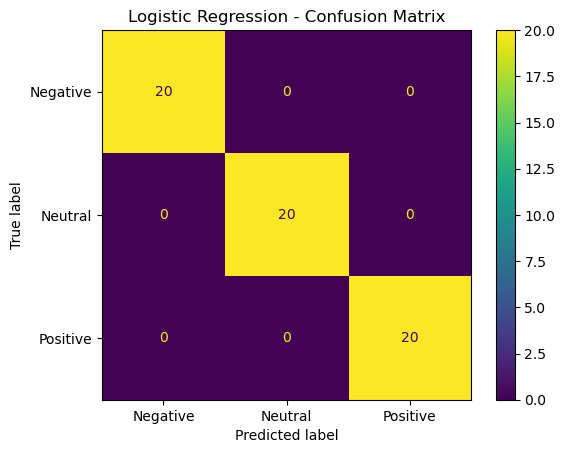

In [45]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Define sentiment class order
labels = ["Negative", "Neutral", "Positive"]

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=labels)

# Display the confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [46]:
# Train a Multinomial Naive Bayes Model
from sklearn.naive_bayes import MultinomialNB

print("Multinomial Naive Bayes imported successfully!")

Multinomial Naive Bayes imported successfully!


In [47]:
# Create the Multinomial Naive Bayes model
nb_model = MultinomialNB()

# Train the model using TF-IDF features
nb_model.fit(X_train, y_train)

print("Multinomial Naive Bayes model trained successfully!")

Multinomial Naive Bayes model trained successfully!


In [48]:
# Predict sentiments using Naive Bayes
y_pred_nb = nb_model.predict(X_test)

# Display actual and predicted sentiments
nb_results = pd.DataFrame({
    "Actual Sentiment": y_test.values,
    "Predicted Sentiment": y_pred_nb
})

print(nb_results.head(10))

  Actual Sentiment Predicted Sentiment
0         Negative            Negative
1         Negative            Negative
2         Positive            Positive
3         Positive            Positive
4         Positive            Positive
5         Negative            Negative
6          Neutral             Neutral
7         Negative            Negative
8         Positive            Positive
9         Negative            Negative


In [49]:
from sklearn.metrics import accuracy_score

# Calculate Naive Bayes accuracy
nb_accuracy = accuracy_score(y_test, y_pred_nb)

print("Multinomial Naive Bayes Accuracy:", round(nb_accuracy * 100, 2), "%")

Multinomial Naive Bayes Accuracy: 100.0 %


In [50]:
# Compare both machine-learning models

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Multinomial Naive Bayes"
    ],
    "Accuracy (%)": [
        round(accuracy * 100, 2),
        round(nb_accuracy * 100, 2)
    ]
})

print(model_comparison)

                     Model  Accuracy (%)
0      Logistic Regression         100.0
1  Multinomial Naive Bayes         100.0


In [51]:
from sklearn.metrics import classification_report

# Classification report for Logistic Regression
print("Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred))

# Classification report for Multinomial Naive Bayes
print("\nMultinomial Naive Bayes Classification Report:")
print(classification_report(y_test, y_pred_nb))

Logistic Regression Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        20
     Neutral       1.00      1.00      1.00        20
    Positive       1.00      1.00      1.00        20

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60


Multinomial Naive Bayes Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        20
     Neutral       1.00      1.00      1.00        20
    Positive       1.00      1.00      1.00        20

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



In [52]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
lr_cv_model = LogisticRegression(max_iter=1000, random_state=42)

# Perform 5-fold cross-validation
cv_scores = cross_val_score(lr_cv_model,X_train,y_train,cv=5,scoring="accuracy")

# Display the results
print("Cross-validation scores:", cv_scores)
print("Mean cross-validation accuracy:", round(cv_scores.mean() * 100, 2), "%")

Cross-validation scores: [1.         1.         1.         0.95833333 1.        ]
Mean cross-validation accuracy: 99.17 %


In [53]:
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import MultinomialNB

# Create the Multinomial Naive Bayes model
nb_cv_model = MultinomialNB()

# Perform 5-fold cross-validation
nb_cv_scores = cross_val_score(nb_cv_model,X_train,y_train,cv=5,scoring="accuracy")

# Display the results
print("Cross-validation scores:", nb_cv_scores)
print(
    "Mean cross-validation accuracy:",
    round(nb_cv_scores.mean() * 100, 2),
    "%"
)

Cross-validation scores: [1.         1.         1.         0.97916667 1.        ]
Mean cross-validation accuracy: 99.58 %


In [54]:
import pandas as pd

# Compare cross-validation results
cv_comparison = pd.DataFrame({
    "Model": ["Logistic Regression","Multinomial Naive Bayes"],"Mean CV Accuracy (%)": [round(cv_scores.mean() * 100, 2),round(nb_cv_scores.mean() * 100, 2)]
})

print(cv_comparison)

                     Model  Mean CV Accuracy (%)
0      Logistic Regression                 99.17
1  Multinomial Naive Bayes                 99.58


In [55]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Create the complete sentiment analysis pipeline
final_model = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=3000)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

# Train the pipeline using the training text
final_model.fit(X_train_text, y_train)

print("Final Logistic Regression pipeline trained successfully!")

Final Logistic Regression pipeline trained successfully!


In [56]:
sample_reviews = [
    "The product is excellent and I am very happy",
    "The product is terrible and completely disappointing",
    "The product is okay and meets basic expectations"
]

predictions = final_model.predict(sample_reviews)

for review, sentiment in zip(sample_reviews, predictions):
    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("-" * 50)

Review: The product is excellent and I am very happy
Predicted Sentiment: Positive
--------------------------------------------------
Review: The product is terrible and completely disappointing
Predicted Sentiment: Negative
--------------------------------------------------
Review: The product is okay and meets basic expectations
Predicted Sentiment: Positive
--------------------------------------------------


In [57]:
import joblib
import os

# Create a folder to store the trained model
os.makedirs("models", exist_ok=True)

# Save the complete pipeline
joblib.dump(final_model, "models/sentiment_model.pkl")

print("Model saved successfully!")
print("Model location:", os.path.abspath("models/sentiment_model.pkl"))

Model saved successfully!
Model location: C:\Users\Nitro V15\Documents\Internship_projects\sentiment_analysis_pro2\notebbok\models\sentiment_model.pkl


In [58]:
import os

model_path = "models/sentiment_model.pkl"

if os.path.exists(model_path):
    print("Model file exists.")
    print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")
else:
    print("Model file not found.")

Model file exists.
File size: 17.44 KB


In [59]:
import os
print(os.getcwd())

C:\Users\Nitro V15\Documents\Internship_projects\sentiment_analysis_pro2\notebbok


In [60]:
import os

print("Current folder:", os.getcwd())
print("Model exists:", os.path.exists("models/sentiment_model.pkl"))

Current folder: C:\Users\Nitro V15\Documents\Internship_projects\sentiment_analysis_pro2\notebbok
Model exists: True


In [66]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import joblib
import os

# Combine existing and additional reviews
df_updated = pd.concat(
    [
        df_unique[["review_text", "sentiment"]],
        extra_reviews
    ],
    ignore_index=True
)

# Split the data
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df_updated["review_text"],
    df_updated["sentiment"],
    test_size=0.20,
    random_state=42,
    stratify=df_updated["sentiment"]
)

# Build and train the model
final_model = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=3000)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

final_model.fit(X_train_text, y_train)

# Evaluate the model
y_pred = final_model.predict(X_test_text)
accuracy = accuracy_score(y_test, y_pred)

print("Updated Model Accuracy:", round(accuracy * 100, 2), "%")

# Save the updated model
os.makedirs("models", exist_ok=True)
joblib.dump(final_model, "models/sentiment_model.pkl")

print("Updated model saved successfully!")

Updated Model Accuracy: 96.88 %
Updated model saved successfully!


In [67]:
test_reviews = [
    "This product is bad quality",
    "The delivered product was damaged",
    "The product is excellent",
    "The package arrived today"
]

for review, prediction in zip(
    test_reviews,
    final_model.predict(test_reviews)
):
    print("Review:", review)
    print("Predicted Sentiment:", prediction)
    print("-" * 40)

Review: This product is bad quality
Predicted Sentiment: Positive
----------------------------------------
Review: The delivered product was damaged
Predicted Sentiment: Negative
----------------------------------------
Review: The product is excellent
Predicted Sentiment: Positive
----------------------------------------
Review: The package arrived today
Predicted Sentiment: Neutral
----------------------------------------
